In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from src.data_info import *
from src.cleaning import *

df = load_data("data/vgsales.csv")

print("Before cleaning:")
size_data(df)
display(is_missing(df))

repartition(df)

df = clean_data(df)

print("\nAfter cleaning:")
size_data(df)

Before cleaning:
Number of line : 16598
Nombre of column : 11


Year            271
Publisher        58
Rank              0
Platform          0
Name              0
Genre             0
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

EU_Sales
<1 000            34.522232
1 000-10 000       9.013134
10 000-100 000    30.750693
100 000-1M        22.882275
1M-20M             2.825642
20M<               0.006025
Name: proportion, dtype: float64

After cleaning:
Number of line : 10667
Nombre of column : 11


In [3]:
from src.preparation import *
X_train, X_test, y_train, y_test = split_data(df)
preprocessor = create_preprocessor(X_train)

Training data: (8533, 8)
Test data: (2134, 8)
Numeric values: ['Year', 'NA_Sales', 'JP_Sales', 'Other_Sales']
Categorical values: ['Name', 'Platform', 'Genre', 'Publisher']


In [4]:
from src.model import *

result_random_forest = train_random_forest(preprocessor, X_train, y_train)

# Récupération du meilleur modèle
best_rf = result_random_forest.best_estimator_

# Prédictions sur les données de test
rf_train_predictions = best_rf.predict(X_train)
rf_test_predictions = best_rf.predict(X_test)

Fitting 5 folds for each of 150 candidates, totalling 750 fits
Best parameters RF: {'model__n_estimators': 800, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_features': 0.3, 'model__max_depth': 25, 'model__bootstrap': False}
RMSE CV RF: 0.2898580333069244


In [5]:
from src.model import *

# Entraînement du modèle HGB
result_hgb = train_hist_gradient_boosting(preprocessor,X_train,y_train)

# Récupération du meilleur modèle
best_hgb = result_hgb.best_estimator_

# Prédictions sur les données de test
hgb_train_predictions = best_hgb.predict(X_train)
hgb_test_predictions = best_hgb.predict(X_test)

Fitting 5 folds for each of 150 candidates, totalling 750 fits
Meilleurs paramètres HGB : {'model__min_samples_leaf': 30, 'model__max_leaf_nodes': 10, 'model__max_iter': 700, 'model__max_depth': 5, 'model__learning_rate': 0.05, 'model__l2_regularization': 10}
RMSE CV HGB : 0.30255394497598376


In [6]:
from src.evaluation import evaluate_model

# Évaluation des modèles
rf_train = evaluate_model(y_train, rf_train_predictions, "Random Forest - Train")
rf_test = evaluate_model(y_test, rf_test_predictions, "Random Forest - Test")

hgb_train = evaluate_model(y_train, hgb_train_predictions, "HistGradientBoosting - Train")
hgb_test = evaluate_model(y_test, hgb_test_predictions, "HistGradientBoosting - Test")

results = pd.DataFrame([
    rf_train,
    rf_test,
    hgb_train,
    hgb_test
])

display(results)


Random Forest - Train
MAE: 0.02599276717467796
RMSE: 0.1582665316995693
R²: 0.9368719946368388

Random Forest - Test
MAE: 0.05657237656947941
RMSE: 0.20283147531409454
R²: 0.8653907090905946

HistGradientBoosting - Train
MAE: 0.06145207585987995
RMSE: 0.24759639680490128
R²: 0.8454985579350629

HistGradientBoosting - Test
MAE: 0.0728801511197864
RMSE: 0.2636698166773884
R²: 0.7725294530487897


,Model,MAE,RMSE,R²
0,Random Forest - Train,0.025993,0.158267,0.936872
1,Random Forest - Test,0.056572,0.202831,0.865391
2,HistGradientBoosting - Train,0.061452,0.247596,0.845499
3,HistGradientBoosting - Test,0.072880,0.263670,0.772529


In [3]:
#a relancer en cas d'erreur
import importlib
import src.preparation
import src.model

importlib.reload(src.preparation)
importlib.reload(src.model)

<module 'src.model' from 'c:\\Users\\mathi\\OneDrive\\Documents\\Projet_IML\\src\\model.py'>

In [7]:
# Compare actual values with predictions
errors = pd.DataFrame({
    "Actual": y_test,
    "Predicted": rf_test_predictions
})

errors["Absolute_Error"] = abs(
    errors["Actual"] - errors["Predicted"]
)

# Display the 10 largest prediction errors
display(
    errors.sort_values(
        by="Absolute_Error",
        ascending=False
    ).head(10)
)

,Actual,Predicted,Absolute_Error
4,8.89,4.483552,4.406448
9,0.63,3.886963,3.256963
77,6.06,3.371959,2.688041
218,3.75,1.557463,2.192537
24,5.49,3.445667,2.044333
37,5.82,4.002368,1.817632
1,3.58,5.242839,1.662839
30,5.04,3.398125,1.641875
1414,0.13,1.563403,1.433403
246,2.39,1.205333,1.184667


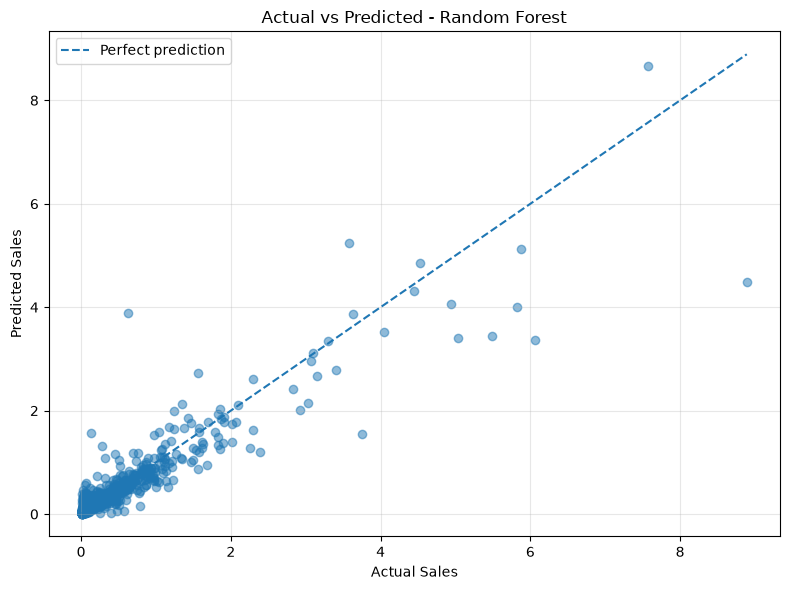

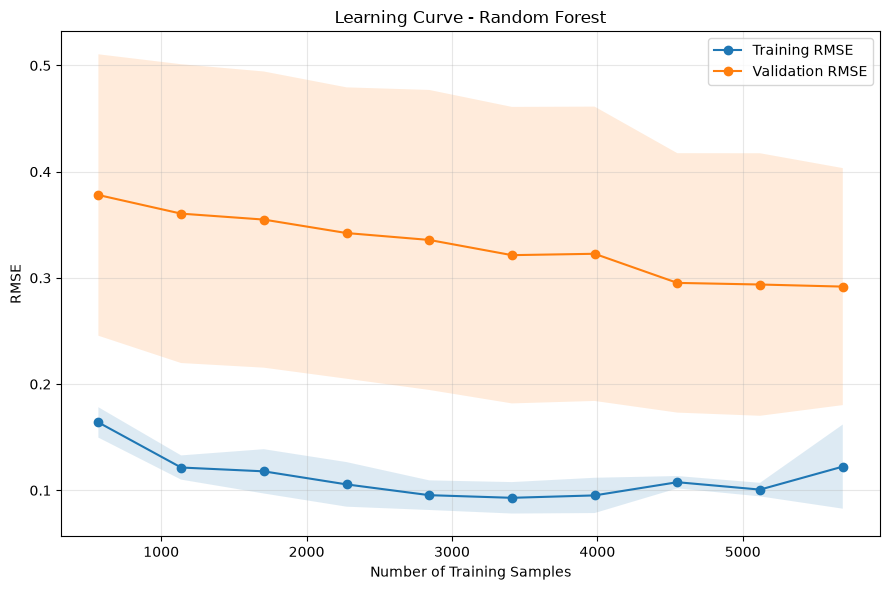

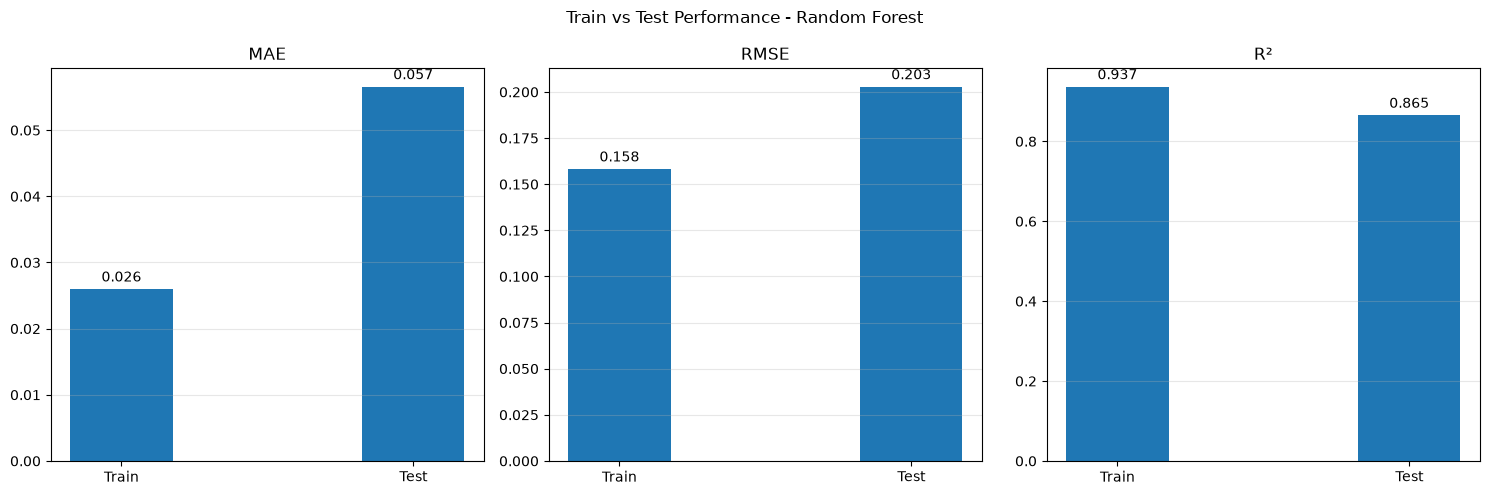

In [8]:
from src.visual import *

# Random Forest
plot_actual_vs_predicted(
    y_test,
    rf_test_predictions,
    "Random Forest"
)

plot_learning_curve(
    best_rf,
    X_train,
    y_train,
    "Random Forest"
)

plot_train_test_comparison(
    y_train,
    y_test,
    rf_train_predictions,
    rf_test_predictions,
    "Random Forest"
)

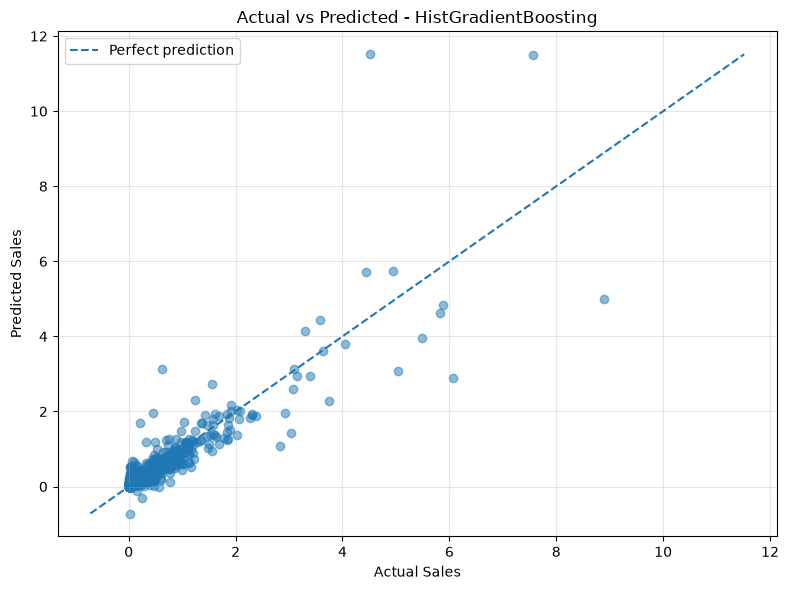

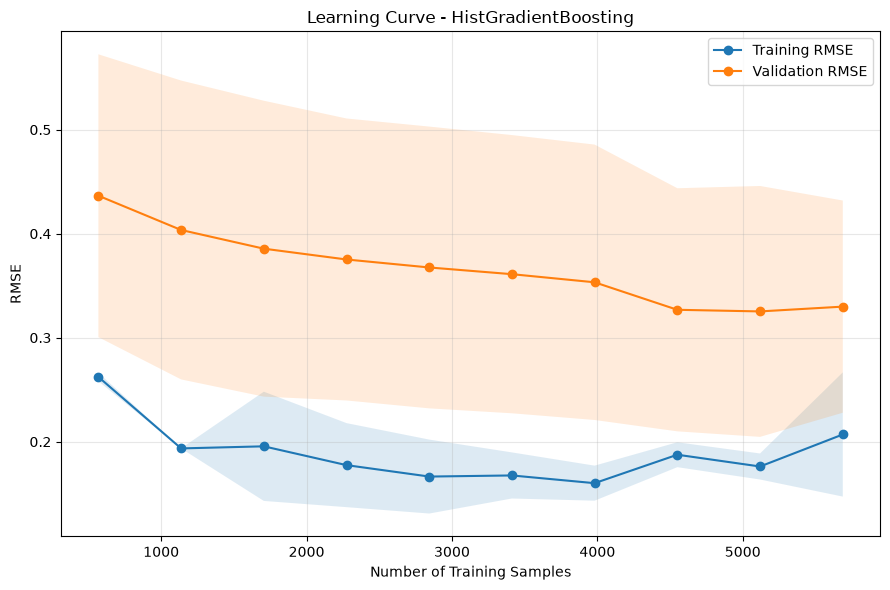

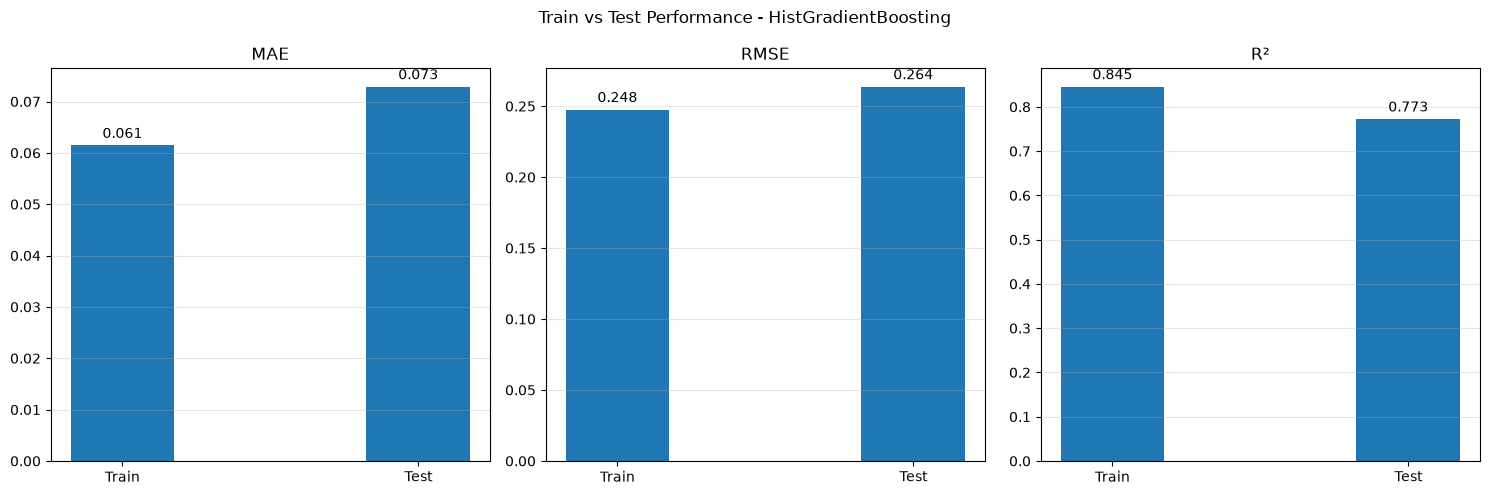

In [9]:
from src.visual import *

# HistGradientBoosting
plot_actual_vs_predicted(
    y_test,
    hgb_test_predictions,
    "HistGradientBoosting"
)

plot_learning_curve(
    best_hgb,
    X_train,
    y_train,
    "HistGradientBoosting"
)
plot_train_test_comparison(
    y_train,
    y_test,
    hgb_train_predictions,
    hgb_test_predictions,
    "HistGradientBoosting"
)